In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# Carregando os dados (mantendo o teu código atual)
df = pd.read_csv('train.csv')

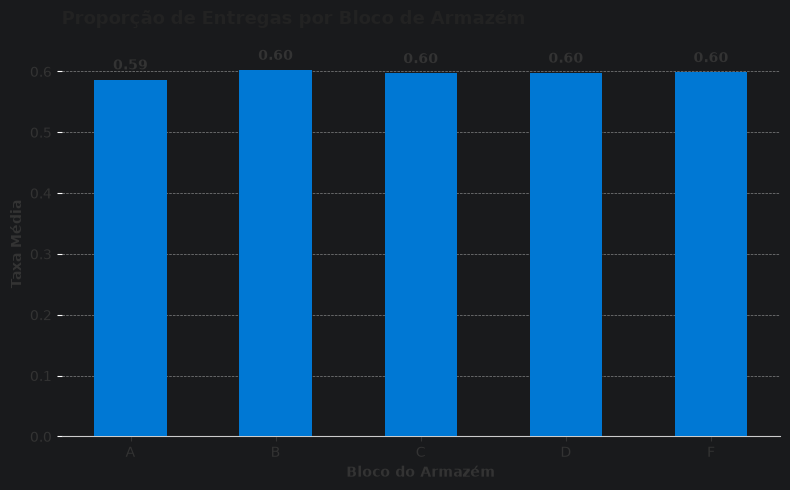

In [3]:
atraso_por_bloco = (
    df.groupby('Warehouse_block')['Reached.on.Time_Y.N'].mean().reset_index()
)

# Configurando a figura
fig, ax = plt.subplots(figsize=(8, 5), dpi=100)

# Criando o gráfico de barras com uma cor corporativa elegante (#0078D4)
barras = ax.bar(
    atraso_por_bloco['Warehouse_block'],
    atraso_por_bloco['Reached.on.Time_Y.N'],
    color='#0078D4',
    width=0.5,
    zorder=3,
)

# Estilo "Clean" (removendo bordas desnecessárias)
for spine in ['top', 'right', 'left']:
  ax.spines[spine].set_visible(False)

ax.spines['bottom'].set_color('#CCCCCC')
ax.grid(axis='y', linestyle='--', alpha=0.6, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)

# Adicionando os valores em cima de cada barra
for barra in barras:
  altura = barra.get_height()
  ax.annotate(
      f'{altura:.2f}',
      xy=(barra.get_x() + barra.get_width() / 2, altura),
      xytext=(0, 5),
      textcoords='offset points',
      ha='center',
      va='bottom',
      fontsize=10,
      color='#333333',
      weight='bold',
  )

# Títulos e rótulos
plt.title(
    'Proporção de Entregas por Bloco de Armazém',
    fontsize=13,
    weight='bold',
    pad=20,
    color='#222222',
    loc='left',
)
plt.xlabel('Bloco do Armazém', fontsize=10, color='#333333', weight='bold')
plt.ylabel('Taxa Média', fontsize=10, color='#333333', weight='bold')
plt.tick_params(axis='x', colors='#333333', labelsize=10)
plt.yticks(color='#333333')

plt.tight_layout()
plt.show()

In [3]:
atrasos_por_envio = pd.crosstab(
    df['Mode_of_Shipment'], df['Reached.on.Time_Y.N']
)

print(atrasos_por_envio)

Reached.on.Time_Y.N     0     1
Mode_of_Shipment               
Flight                708  1069
Road                  725  1035
Ship                 3003  4459


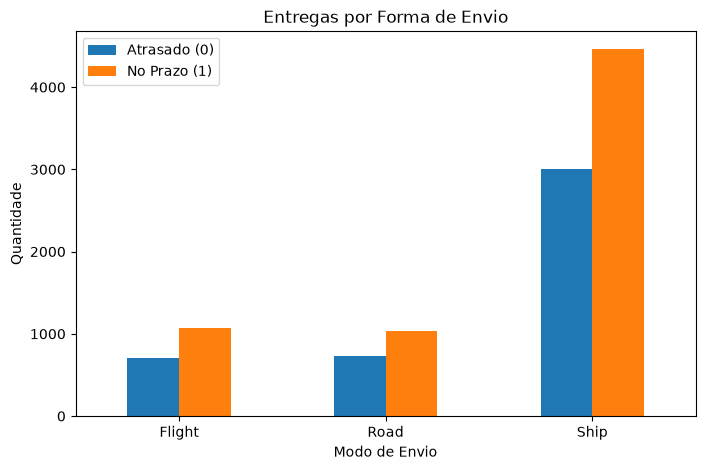

In [4]:
atrasos_por_envio.plot(kind='bar', figsize=(8, 5))

plt.title('Entregas por Forma de Envio')
plt.xlabel('Modo de Envio')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)  # Deixa o nome dos envios retinhos
plt.legend(
    ['Atrasado (0)', 'No Prazo (1)']
)  # Legenda para sabermos quem é quem
plt.show()

In [6]:
# ==========================================
# ANÁLISE 4: Peso Médio vs Atraso
# ==========================================

# Calcula o peso médio dos produtos que atrasaram (0) e dos que chegaram no prazo (1)
peso_por_atraso = (
    df.groupby('Reached.on.Time_Y.N')['Weight_in_gms'].mean().reset_index()
)

print('Peso médio (em gramas) por status de entrega:')
print(peso_por_atraso)

# Criando um gráfico de barras simples


Peso médio (em gramas) por status de entrega:
   Reached.on.Time_Y.N  Weight_in_gms
0                    0    4168.668395
1                    1    3272.640104


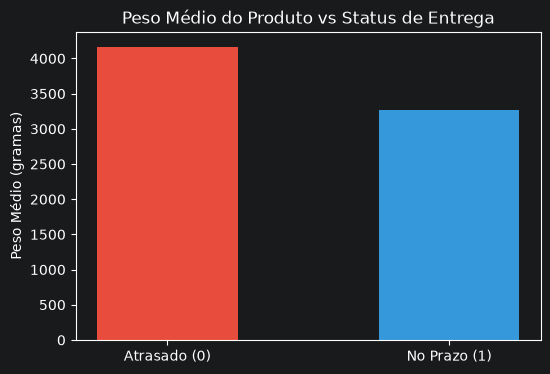

In [7]:
plt.figure(figsize=(6, 4))
plt.bar(
    ['Atrasado (0)', 'No Prazo (1)'],
    peso_por_atraso['Weight_in_gms'],
    color=['#e74c3c', '#3498db'],
    width=0.5,
)

plt.title('Peso Médio do Produto vs Status de Entrega')
plt.ylabel('Peso Médio (gramas)')
plt.show()

In [9]:
avaliacao_por_atraso = (
    df.groupby("Reached.on.Time_Y.N")["Customer_rating"].mean().reset_index()
)
print("avaliação media por atraso :")
print(avaliacao_por_atraso)

avaliação media por atraso :
   Reached.on.Time_Y.N  Customer_rating
0                    0         2.967989
1                    1         3.005790


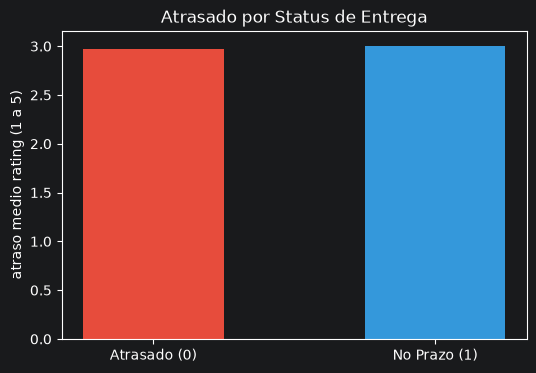

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(
     ['Atrasado (0)', 'No Prazo (1)'],
    avaliacao_por_atraso['Customer_rating'],
    color=['#e74c3c', '#3498db'],
    width=0.5
)
plt.title('Atrasado por Status de Entrega')
plt.ylabel('atraso medio rating (1 a 5)')
plt.show()



In [4]:
# ==========================================
# PREPARAÇÃO PARA MACHINE LEARNING
# ==========================================

# 1. Vamos remover a coluna 'ID' porque ela é apenas um número de série
# e não ajuda o modelo a prever se vai haver atraso ou não.
df_processado = df.drop(columns=['ID'])

# 2. Transformamos todas as colunas de texto em colunas numéricas (0 e 1)
df_ml = pd.get_dummies(df_processado)

# 3. Mostramos as primeiras colunas para ver como ficou
print('Colunas novas criadas pelo One-Hot Encoding:')
print(df_ml.head())

Colunas novas criadas pelo One-Hot Encoding:
   Customer_care_calls  Customer_rating  Cost_of_the_Product  Prior_purchases  \
0                    4                2                  177                3   
1                    4                5                  216                2   
2                    2                2                  183                4   
3                    3                3                  176                4   
4                    2                2                  184                3   

   Discount_offered  Weight_in_gms  Reached.on.Time_Y.N  Warehouse_block_A  \
0                44           1233                    1              False   
1                59           3088                    1              False   
2                48           3374                    1               True   
3                10           1177                    1              False   
4                46           2484                    1              False   


In [9]:
# ==========================================
# 1. SEPARAR FEATURES (X) E TARGET (y)
# ==========================================

# A nossa resposta alvo é saber se chegou no prazo ou não
y = df_ml['Reached.on.Time_Y.N']

# Tudo o resto (exceto a coluna alvo) são as caraterísticas que o modelo vai usar para prever
X = df_ml.drop(columns=['Reached.on.Time_Y.N'])

print('Tamanho das variáveis de entrada (X):', X.shape)
print('Tamanho da variável alvo (y):', y.shape)

Tamanho das variáveis de entrada (X): (10999, 19)
Tamanho da variável alvo (y): (10999,)


In [10]:
# ==========================================
# 2. DIVISÃO EM TREINO E TESTE
# ==========================================
from sklearn.model_selection import train_test_split

# Separamos 80% para treino e 20% para teste
# random_state serve para garantir que a divisão seja sempre igual se você rodar de novo
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Tamanho dos dados de treino (X_train):', X_train.shape)
print('Tamanho dos dados de teste (X_test):', X_test.shape)

Tamanho dos dados de treino (X_train): (8799, 19)
Tamanho dos dados de teste (X_test): (2200, 19)


In [11]:
# ==========================================
# 3. TREINAR O MODELO DE MACHINE LEARNING
# ==========================================
from sklearn.tree import DecisionTreeClassifier

# Criamos o modelo (o "cérebro" vazio)
modelo = DecisionTreeClassifier(random_state=42)

# Treinamos o modelo usando os dados de treino (aqui ele aprende os padrões)
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [12]:
# ==========================================
# 4. AVALIAR O MODELO (PRECISÃO)
# ==========================================
from sklearn.metrics import accuracy_score

# Pedimos ao modelo para prever os resultados usando os dados de teste
previsoes = modelo.predict(X_test)

# Comparamos as previsões do modelo com as respostas reais (y_test)
precisao = accuracy_score(y_test, previsoes)

print(f"Taxa de acerto (Acurácia) do modelo: {precisao * 100:.2f}%")

Taxa de acerto (Acurácia) do modelo: 64.09%


In [13]:
# ==========================================
# TESTANDO UM NOVO MODELO: RANDOM FOREST
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Criamos uma "floresta" com 100 árvores de decisão
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinamos com os mesmos dados de treino
modelo_rf.fit(X_train, y_train)

# Fazemos as previsões com os dados de teste
previsoes_rf = modelo_rf.predict(X_test)

# Calculamos a nova acurácia
precisao_rf = accuracy_score(y_test, previsoes_rf)

print(f'Nova taxa de acerto com Random Forest: {precisao_rf * 100:.2f}%')

Nova taxa de acerto com Random Forest: 65.27%


In [16]:
# Extrai a importância de cada coluna calculada pelo modelo Random Forest
importancias = modelo_rf.feature_importances_

# Junta os nomes das colunas com os respetivos valores de importância
df_importancias = pd.DataFrame(
    {'Variavel': X_train.columns, 'Importancia': importancias}
)

# Ordena da mais importante para a menos importante
df_importancias = df_importancias.sort_values(by='Importancia', ascending=False)

print('Top variáveis mais importantes para o modelo:')
print(df_importancias.head(10))

Top variáveis mais importantes para o modelo:
                     Variavel  Importancia
5               Weight_in_gms     0.266298
4            Discount_offered     0.221118
2         Cost_of_the_Product     0.169882
3             Prior_purchases     0.063647
1             Customer_rating     0.060129
0         Customer_care_calls     0.054618
10          Warehouse_block_F     0.015731
13      Mode_of_Shipment_Ship     0.015000
15     Product_importance_low     0.014089
16  Product_importance_medium     0.013892


Text(0, 0.5, 'Variáveis')

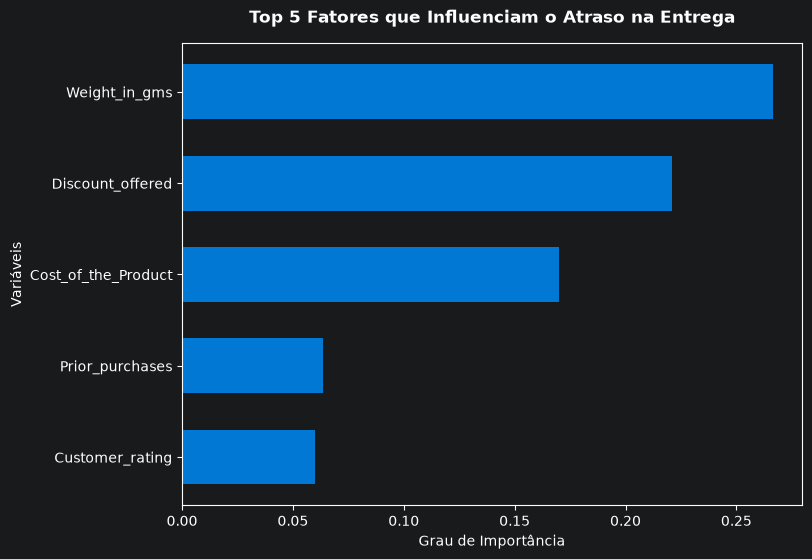

In [18]:
top5 = df_importancias.head(5)
plt.figure(figsize=(8, 6))
plt.barh(
    top5['Variavel'],
    top5['Importancia'],color='#0078D4', height=0.6
)
plt.gca().invert_yaxis()

# Títulos e rótulos limpos
plt.title(
    'Top 5 Fatores que Influenciam o Atraso na Entrega',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Grau de Importância', fontsize=10)
plt.ylabel('Variáveis', fontsize=10)

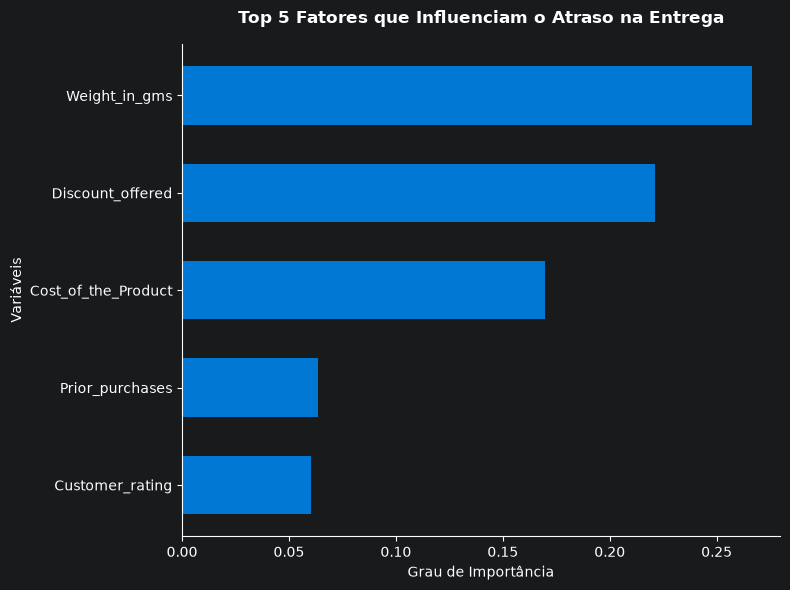

In [19]:
top5 = df_importancias.head(5)
plt.figure(figsize=(8, 6))
plt.barh(
    top5['Variavel'],
    top5['Importancia'],color='#0078D4', height=0.6
)
plt.gca().invert_yaxis()

# Títulos e rótulos limpos
plt.title(
    'Top 5 Fatores que Influenciam o Atraso na Entrega',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Grau de Importância', fontsize=10)
plt.ylabel('Variáveis', fontsize=10)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
maior_taxa_de_atraso = (
    df.groupby('Mode_of_Shipment')['Reached.on.Time_Y.N'].mean()
)
print(maior_taxa_de_atraso)

Mode_of_Shipment
Flight    0.601576
Road      0.588068
Ship      0.597561
Name: Reached.on.Time_Y.N, dtype: float64


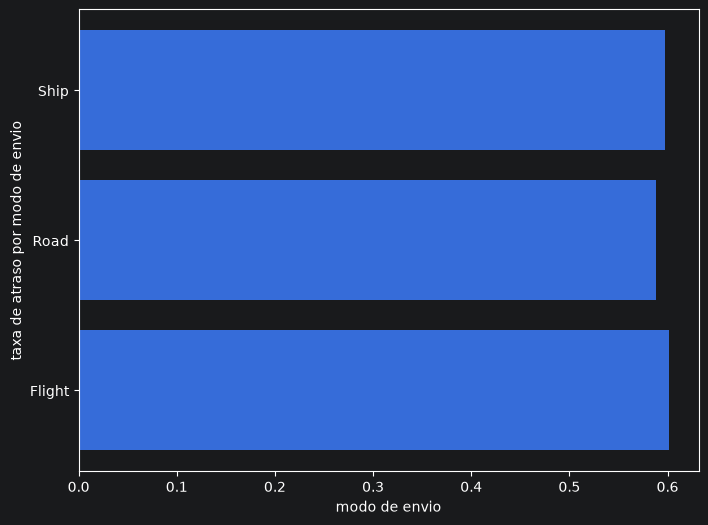

In [32]:
plt.figure(figsize=(8, 6))
plt.barh(
    maior_taxa_de_atraso.index,maior_taxa_de_atraso.values
)
plt.xlabel("modo de envio", fontsize=10)
plt.ylabel("taxa de atraso por modo de envio")
plt.show()